# Escolaridad e internet por perfil (Estadísticas Censales a Escalas Geoelectorales 2020)

El CCPC no trae escolaridad. Se toma del producto conjunto INEGI-INE **Estadísticas Censales a
Escalas Geoelectorales 2020** (ECEG): indicadores del Censo de Población y Vivienda 2020 asignados
a cada sección electoral del marco seccional del INE con corte de enero de 2021.

- Variable principal: grado promedio de escolaridad de la población de 15 años y más (`GRAPROES`),
  por sexo (`GRAPROES_F`, `GRAPROES_M`).
- Variable complementaria: % de la población de 18 años y más con educación posbásica (`P18YM_PB`).
- % de viviendas particulares habitadas con internet (`VPH_INTER / VIVPARH_CV`), util para elegir
  canales de campaña. Es dato de la vivienda: igual para ambos sexos.
- Cada celda (sección x sexo x grupo de edad) recibe el valor de su sección para su sexo.

Salidas en `DATA/PREPROCESSED/`: `secciones_eceg_2020.parquet`, `escolaridad_perfiles.csv`,
`escolaridad_subperfiles.csv`, `escolaridad_perfil_tiposec.csv`.

## 1. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 100, "figure.facecolor": "white"})

## 2. Parametros y rutas

Tramos de grado promedio: menos de 8 (por debajo de secundaria completa), 8 a 10 (secundaria),
10 a 12 (media superior incompleta) y 12 o más (media superior completa o más).

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"
ARCHIVO_ECEG = ROOT / "DATA" / "RAW" / "eceg_2020" / "conjunto_de_datos" / "INE_SECCION_2020.csv"
LLAVES = ["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"]

COLUMNAS_ECEG = [
    "ENTIDAD", "SECCION", "POBTOT", "P_15YMAS",
    "P_18YMAS", "P_18YMAS_F", "P_18YMAS_M",
    "GRAPROES", "GRAPROES_F", "GRAPROES_M",
    "P18YM_PB", "P18YM_PB_F", "P18YM_PB_M",
    "VIVPARH_CV", "VPH_INTER",
]
CORTES_ESC = [0, 8, 10, 12, 30]
TRAMOS_ESC = ["<8", "8-10", "10-12", "12+"]
COLORES_TRAMO = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
TIPOSEC_NOMBRE = {"U": "Urbana", "M": "Mixta", "R": "Rural"}

### 2.1 Funciones auxiliares

In [3]:
def media_ponderada(df, col, por):
    grupos = [df[c] for c in por]
    wx = (df[col] * df["peso"]).groupby(grupos).sum()
    return wx / df["peso"].where(df[col].notna()).groupby(grupos).sum()


def distribucion(df, por, col):
    t = df.pivot_table(index=por, columns=col, values="peso", aggfunc="sum", observed=False)
    return t.div(t.sum(axis=1), axis=0) * 100


def corr_ponderada(x, y, w):
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    return np.average((x - mx) * (y - my), weights=w) / np.sqrt(np.average((x - mx) ** 2, weights=w) * np.average((y - my) ** 2, weights=w))


def resumen_escolaridad(df, por):
    out = pd.DataFrame({
        "personas": df.groupby(por)["peso"].sum(),
        "escolaridad": media_ponderada(df, "escolaridad", por),
        "pct_posbasica": media_ponderada(df, "pct_posbasica", por),
        "pct_internet": media_ponderada(df, "pct_internet", por),
    })
    dist = distribucion(df, por, "tramo_esc")
    dist.columns = [f"pct_esc_{c}" for c in dist.columns]
    return out.join(dist)

## 3. Carga de la ECEG por sección

El CSV viene en latin-1. Los valores negativos (`-6`) son el código de confidencialidad del INEGI y
las secciones sin población traen `0`; ambos se tratan como dato faltante.

In [4]:
eceg = pd.read_csv(ARCHIVO_ECEG, encoding="latin1", usecols=COLUMNAS_ECEG)
eceg = eceg.rename(columns={"ENTIDAD": "EDOCVE"})
assert not eceg.duplicated(["EDOCVE", "SECCION"]).any()

valores = eceg.columns.drop(["EDOCVE", "SECCION"])
print("Valores negativos por columna:", (eceg[valores] < 0).sum()[lambda s: s > 0].to_dict())
eceg[valores] = eceg[valores].mask(eceg[valores] < 0)
sin_poblacion = eceg["P_15YMAS"].fillna(0) == 0
eceg.loc[sin_poblacion, ["GRAPROES", "GRAPROES_F", "GRAPROES_M"]] = np.nan
print(f"Secciones: {len(eceg):,}  sin poblacion de 15+: {sin_poblacion.sum()}")

Valores negativos por columna: {'P_15YMAS': 6, 'P_18YMAS': 6, 'P_18YMAS_F': 6, 'P_18YMAS_M': 6, 'P18YM_PB': 6, 'P18YM_PB_F': 6, 'P18YM_PB_M': 6, 'GRAPROES': 6, 'GRAPROES_F': 6, 'GRAPROES_M': 6, 'VIVPARH_CV': 6, 'VPH_INTER': 6}
Secciones: 68,806  sin poblacion de 15+: 72


### 3.1 Indicadores por sección y sexo

Porcentaje con educación posbásica sobre la población de 18 años y más del mismo sexo, y porcentaje
de viviendas particulares habitadas con internet.

In [5]:
for sufijo in ["", "_F", "_M"]:
    eceg[f"PCT_POSBASICA{sufijo}"] = eceg[f"P18YM_PB{sufijo}"] / eceg[f"P_18YMAS{sufijo}"].where(eceg[f"P_18YMAS{sufijo}"] > 0) * 100

eceg["PCT_INTERNET"] = eceg["VPH_INTER"] / eceg["VIVPARH_CV"].where(eceg["VIVPARH_CV"] > 0) * 100

eceg[["GRAPROES", "GRAPROES_F", "GRAPROES_M", "PCT_POSBASICA", "PCT_INTERNET"]].describe().round(2)

,GRAPROES,GRAPROES_F,GRAPROES_M,PCT_POSBASICA,PCT_INTERNET
count,68734.00,68734.00,68734.00,68734.00,68730.00
mean,9.39,9.30,9.50,42.26,47.44
std,2.32,2.23,2.45,22.15,27.98
min,0.69,0.00,0.76,0.00,0.00
25%,7.65,7.71,7.63,23.95,21.90
50%,9.39,9.31,9.50,41.27,52.61
75%,10.92,10.76,11.12,58.30,70.40
max,16.60,15.81,17.57,100.00,100.00


### 3.2 Guardar tabla de secciones

In [6]:
secciones_eceg = eceg[["EDOCVE", "SECCION", "POBTOT", "P_15YMAS", "P_18YMAS",
                       "GRAPROES", "GRAPROES_F", "GRAPROES_M",
                       "PCT_POSBASICA", "PCT_POSBASICA_F", "PCT_POSBASICA_M", "PCT_INTERNET"]]
secciones_eceg.to_parquet(DIR_PREPROCESSED / "secciones_eceg_2020.parquet", index=False)
print(f"secciones_eceg_2020.parquet: {len(secciones_eceg):,} filas")

secciones_eceg_2020.parquet: 68,806 filas


## 4. Union con las celdas

Celdas con perfil y subperfil del notebook 09 (clases latentes) y tipo de sección del 03.
Cada celda toma la escolaridad de su sección para su sexo; el sexo no binario (solo 2024 y sin
celdas con historial completo) usaria el total.

In [7]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_subperfiles.parquet")
tipo = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet", columns=LLAVES + ["TIPOSEC"])
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)
tipo["GRUPO_EDAD"] = tipo["GRUPO_EDAD"].astype(str)
celdas = celdas.merge(tipo, on=LLAVES, how="left")
celdas["EDOCVE"] = celdas["EDOCVE"].astype(int)

celdas = celdas.merge(secciones_eceg, on=["EDOCVE", "SECCION"], how="left", indicator=True)
union = celdas["_merge"] == "both"
print(f"Celdas con seccion en la ECEG: {union.mean():.2%}  personas: {celdas.loc[union, 'peso'].sum() / celdas['peso'].sum():.2%}")
celdas = celdas.drop(columns="_merge")

Celdas con seccion en la ECEG: 100.00%  personas: 100.00%


### 4.1 Escolaridad de la celda segun su sexo

In [8]:
sexo = celdas["SEXO"]
celdas["escolaridad"] = np.select([sexo == 1, sexo == 0], [celdas["GRAPROES_F"], celdas["GRAPROES_M"]], celdas["GRAPROES"])
celdas["pct_posbasica"] = np.select([sexo == 1, sexo == 0], [celdas["PCT_POSBASICA_F"], celdas["PCT_POSBASICA_M"]], celdas["PCT_POSBASICA"])
celdas["pct_internet"] = celdas["PCT_INTERNET"]
celdas["tramo_esc"] = pd.cut(celdas["escolaridad"], CORTES_ESC, labels=TRAMOS_ESC, right=False)

sin_dato = celdas["escolaridad"].isna()
print(f"Personas sin escolaridad (secciones confidenciales o vacias): {celdas.loc[sin_dato, 'peso'].sum():,}")
nacional = np.average(celdas.loc[~sin_dato, "escolaridad"], weights=celdas.loc[~sin_dato, "peso"])
print(f"Grado promedio ponderado por votantes: {nacional:.2f}")

Personas sin escolaridad (secciones confidenciales o vacias): 10,279
Grado promedio ponderado por votantes: 9.68


## 5. Escolaridad y participación por sección

Antes de caracterizar perfiles: participación promedio 2009-2024 de las secciones del 03 segun su
grado promedio de escolaridad y tipo de sección, ponderada por lista nominal 2024.

In [9]:
secciones = pd.read_parquet(DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "promedio", "TIPOSEC", "LN2024"])
secciones["EDOCVE"] = secciones["EDOCVE"].astype(int)
secciones = secciones.merge(secciones_eceg[["EDOCVE", "SECCION", "GRAPROES"]], on=["EDOCVE", "SECCION"]).dropna(subset=["GRAPROES"])
secciones["peso"] = secciones["LN2024"]
secciones["tramo_esc"] = pd.cut(secciones["GRAPROES"], CORTES_ESC, labels=TRAMOS_ESC, right=False)

print(f"Secciones: {len(secciones):,}  correlacion ponderada escolaridad-participacion: "
      f"{corr_ponderada(secciones['GRAPROES'], secciones['promedio'], secciones['peso']):.2f}")
for t, g in secciones.groupby("TIPOSEC"):
    print(f"  {TIPOSEC_NOMBRE[t]}: {corr_ponderada(g['GRAPROES'], g['promedio'], g['peso']):.2f}")

media_ponderada(secciones, "promedio", ["tramo_esc", "TIPOSEC"]).unstack().rename(columns=TIPOSEC_NOMBRE).round(1)

Secciones: 54,864  correlacion ponderada escolaridad-participacion: 0.10
  Mixta: -0.04
  Rural: 0.02
  Urbana: 0.41


TIPOSEC,Mixta,Rural,Urbana
tramo_esc,,,
<8,56.2,58.6,53.0
8-10,55.1,59.4,50.9
10-12,53.6,57.1,54.5
12+,56.8,60.5,60.6


## 6. Escolaridad por perfil

In [10]:
res_perfil = resumen_escolaridad(celdas, ["perfil"])
res_perfil.round(2)

,personas,escolaridad,pct_posbasica,pct_internet,pct_esc_<8,pct_esc_8-10,pct_esc_10-12,pct_esc_12+
perfil,,,,,,,,
0,15253119,9.33,41.01,50.62,18.84,47.77,28.32,5.07
1,5934456,9.12,38.19,49.25,23.86,47.41,23.93,4.80
2,13265429,10.00,48.62,54.56,15.69,33.72,34.88,15.72
3,11639641,9.60,43.63,51.78,19.17,41.60,28.35,10.88
4,8413205,10.11,49.86,53.31,19.95,28.09,30.18,21.78
5,16697727,9.78,46.17,49.12,25.51,29.87,25.18,19.44


### 6.1 Distribución por tramo de escolaridad

Porcentaje de las personas de cada perfil segun el grado promedio de su sección (para su sexo).

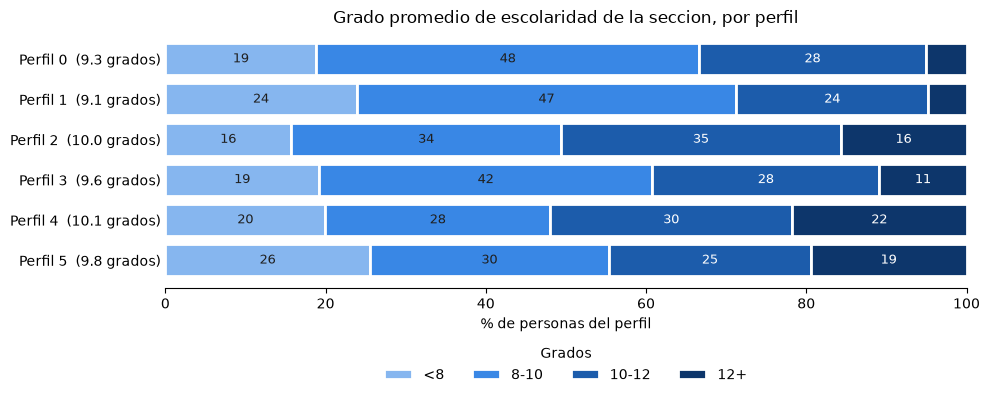

In [11]:
dist = res_perfil[[f"pct_esc_{t}" for t in TRAMOS_ESC]]
fig, ax = plt.subplots(figsize=(10, 4.2))
izquierda = np.zeros(len(dist))
for tramo, color, oscuro in zip(TRAMOS_ESC, COLORES_TRAMO, [False, False, True, True]):
    v = dist[f"pct_esc_{tramo}"].to_numpy()
    ax.barh(dist.index.astype(str), v, left=izquierda, color=color, edgecolor="white", linewidth=2, label=tramo)
    for y, (x0, w) in enumerate(zip(izquierda, v)):
        if w >= 8:
            ax.text(x0 + w / 2, y, f"{w:.0f}", ha="center", va="center", fontsize=9, color="white" if oscuro else "#1f1f1f")
    izquierda += v
ax.set_yticks(range(len(dist)))
ax.set_yticklabels([f"Perfil {p}  ({res_perfil.loc[p, 'escolaridad']:.1f} grados)" for p in dist.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% de personas del perfil")
ax.set_title("Grado promedio de escolaridad de la seccion, por perfil")
ax.legend(title="Grados", ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### 6.2 Por perfil y tipo de sección

Separa el efecto territorial: un perfil con muchas secciones rurales puede tener menor escolaridad
promedio aunque sus secciones urbanas sean de escolaridad alta.

In [12]:
res_tiposec = resumen_escolaridad(celdas, ["perfil", "TIPOSEC"])
tabla = res_tiposec["escolaridad"].unstack().rename(columns=TIPOSEC_NOMBRE)[["Urbana", "Mixta", "Rural"]]
pct_tipo = (res_tiposec["personas"] / res_tiposec.groupby(level="perfil")["personas"].transform("sum") * 100).unstack().rename(columns=TIPOSEC_NOMBRE)
tabla.round(2).join(pct_tipo[["Urbana", "Mixta", "Rural"]].round(1), rsuffix=" (% personas)")

TIPOSEC,Urbana,Mixta,Rural,Urbana (% personas),Mixta (% personas),Rural (% personas)
perfil,,,,,,
0,9.81,8.84,7.11,73.3,13.7,13.0
1,9.71,8.95,7.28,63.8,17.5,18.7
2,10.61,8.94,7.19,76.3,12.0,11.7
3,10.28,9.05,7.42,67.5,15.1,17.4
4,10.99,8.70,6.93,72.7,12.9,14.5
5,11.01,8.75,7.17,62.4,13.6,24.0


## 7. Escolaridad por subperfil

In [13]:
res_sub = resumen_escolaridad(celdas, ["perfil", "subperfil"])
res_sub["pct_perfil"] = res_sub["personas"] / res_sub.groupby(level="perfil")["personas"].transform("sum") * 100
res_sub.round(2)

personas  escolaridad  pct_posbasica  pct_internet  \
perfil subperfil                                                       
0      0.1         2356390         8.18          29.01         38.86   
       0.2         2777656         9.53          43.42         51.63   
       0.3         4586956         9.45          41.62         53.14   
       0.4         3177680        10.32          51.27         60.67   
       0.5         2354437         8.66          35.15         42.76   
1      1.1         1657911         8.59          32.46         43.04   
       1.2         2461403         9.46          41.65         52.54   
       1.3         1815142         9.15          38.74         50.46   
2      2.1         1650623        10.06          48.85         50.46   
       2.2         3545641        10.94          57.91         66.05   
       2.3         3403187        10.13          49.58         57.68   
       2.4         2749250         9.50          43.87         47.95   
       2.5         1916728         8.72          36.34         40.81   
3      3.1         2584664        10.45          52.51         60.78   
       3.2         2823201         9.56          42.96         51.82   
       3.3         2426802         9.78          45.67         52.90   
       3.4         2221206         9.19          39.40         48.09   
       3.5         1583768         8.59          33.12         40.52   
4      4.1         2096002        11.17          60.03         66.85   
       4.2         2760920        10.47          53.29         58.59   
       4.3         1897720         9.42          43.21         42.04   
       4.4         1658563         8.95          38.90         40.32   
5      5.1         3846091        10.83          56.73         63.30   
       5.2         3512479         9.84          46.35         51.02   
       5.3         2297323         9.79          47.62         48.13   
       5.4         3855088         9.53          43.86         45.30   
       5.5         3186746         8.73          34.98         35.25   

                  pct_esc_<8  pct_esc_8-10  pct_esc_10-12  pct_esc_12+  \
perfil subperfil                                                         
0      0.1             42.52         45.59          11.24         0.64   
       0.2             15.93         46.16          31.87         6.04   
       0.3             10.67         58.48          27.63         3.22   
       0.4              4.31         38.05          45.88        11.76   
       0.5             34.13         44.10          18.85         2.91   
1      1.1             35.00         46.48          15.80         2.72   
       1.2             15.19         51.12          27.93         5.76   
       1.3             25.45         43.25          25.92         5.38   
2      2.1             19.11         31.66          28.31        20.93   
       2.2              2.85         24.02          49.64        23.49   
       2.3              8.52         40.17          37.98        13.33   
       2.4             24.34         36.03          27.13        12.51   
       2.5             36.80         38.66          18.83         5.72   
3      3.1              6.68         34.41          41.13        17.77   
       3.2             16.11         47.24          28.54         8.11   
       3.3             17.01         40.30          29.56        13.13   
       3.4             27.38         42.30          21.78         8.54   
       3.5             36.84         44.31          14.47         4.38   
4      4.1              4.49         20.47          43.65        31.40   
       4.2             12.10         29.52          34.96        23.43   
       4.3             32.57         30.55          19.36        17.52   
       4.4             38.16         32.53          17.58        11.74   
5      5.1              8.36         24.30          39.37        27.97   
       5.2             17.87         37.30          29.89        14.94   
     

## 8. Guardar resultados

In [14]:
res_perfil.round(3).to_csv(DIR_PREPROCESSED / "escolaridad_perfiles.csv")
res_sub.round(3).to_csv(DIR_PREPROCESSED / "escolaridad_subperfiles.csv")
res_tiposec.round(3).to_csv(DIR_PREPROCESSED / "escolaridad_perfil_tiposec.csv")
print("Guardados: escolaridad_perfiles.csv, escolaridad_subperfiles.csv, escolaridad_perfil_tiposec.csv")

Guardados: escolaridad_perfiles.csv, escolaridad_subperfiles.csv, escolaridad_perfil_tiposec.csv


## 9. Limitaciones

- **Dato ecológico:** la escolaridad es el promedio de la sección para el sexo de la celda (15 años
  y más), no la de su grupo de edad ni la de las personas que votaron. Describe el entorno
  educativo de cada perfil, no la escolaridad individual.
- **Fechas distintas:** censo de marzo de 2020 contra lista nominal de 2024.
- **Marco seccional:** corte de enero de 2021; todas las secciones de las celdas existen en la ECEG.